# Chapitre 3 - Cours 2 : Évaluation exacte, correction fonctionnelle et similarité lexicale

Ce notebook couvre la section *Exact Evaluation* du livre : la **correction
fonctionnelle** (sous-section *Functional Correctness*) et la **similarité avec des
données de référence** dans ses variantes exacte et lexicale (sous-sections *Similarity
Measurements Against Reference Data*, *Exact match*, *Lexical similarity*). La similarité
sémantique et les embeddings font l'objet du cours 3.

**Plan.**

1. Évaluation exacte ou subjective, et le harnais d'évaluation de code.
2. Correction fonctionnelle : exécuter le code généré sur des tests unitaires.
3. pass@k : définition, estimateur non biaisé (démonstration) et simulation.
4. Expérience : Qwen2.5-0.5B sur un mini-banc de dix problèmes Python.
5. Correspondance exacte et ses variantes.
6. Similarité lexicale : distance d'édition, n-grammes, BLEU et ROUGE implémentés.
7. Les limites des métriques lexicales (références incomplètes, BLEU contre tests).

In [1]:
import math
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from aie import ch03_evaluation as ev
from aie import llm
from aie.diagrams import Diagram
from aie.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                          annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
llm.seed_everything(0)
pd.set_option("display.precision", 3)

## 1. Évaluation exacte ou subjective (section *Exact Evaluation*)

Le livre distingue deux régimes :

- **exact** : le verdict est sans ambiguïté (au QCM, B au lieu de A est faux, quel que
  soit le correcteur) ;
- **subjectif** : le verdict dépend de l'évaluateur (une dissertation, ou un juge IA dont
  le score change avec le modèle et le prompt, cours 3).

Deux familles de méthodes donnent des scores exacts sur des réponses **ouvertes** : la
correction fonctionnelle et la similarité avec des références. Le cas fermé
(classification) est bien connu et laissé de côté. Le schéma montre le harnais utilisé par
les benchmarks de code comme HumanEval ou MBPP, que nous allons reconstruire.

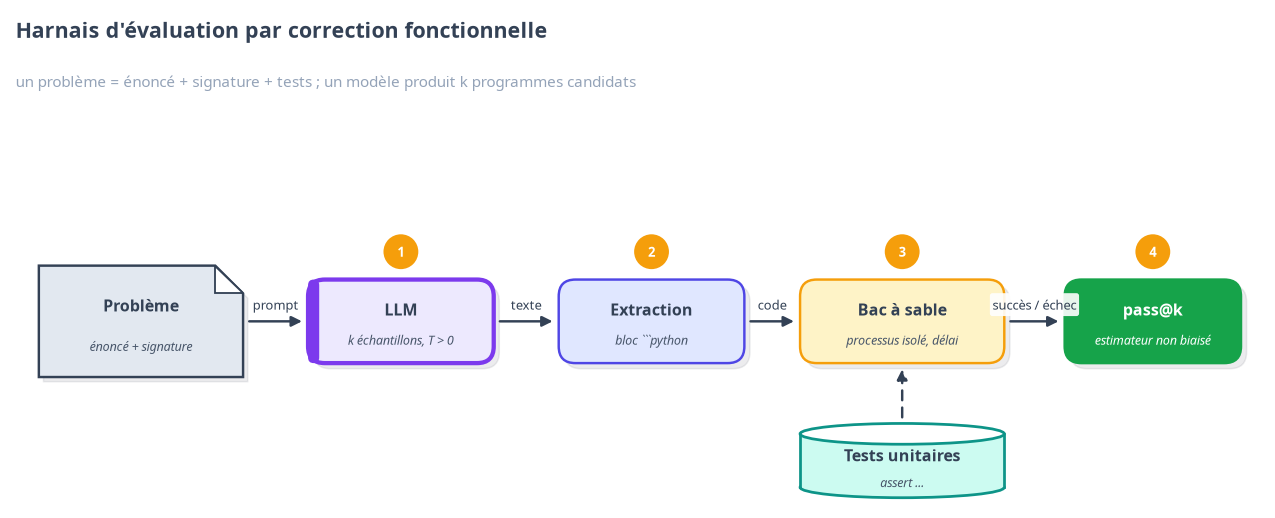

In [2]:
d = Diagram(13.5, 4.4, title="Harnais d'évaluation par correction fonctionnelle",
            subtitle="un problème = énoncé + signature + tests ; un modèle produit k programmes candidats")
d.box("pb", 1.4, 2.0, "Problème", sub="énoncé + signature", color=SLATE, kind="doc", w=2.2, h=1.2)
d.box("llm", 4.2, 2.0, "LLM", sub="k échantillons, T > 0", color=VIOLET, kind="model", w=2.0)
d.box("ext", 6.9, 2.0, "Extraction", sub="bloc ```python", color=INDIGO, w=2.0)
d.box("sb", 9.6, 2.0, "Bac à sable", sub="processus isolé, délai", color=AMBER, w=2.2)
d.box("tests", 9.6, 0.5, "Tests unitaires", sub="assert ...", color=TEAL, kind="db", w=2.2, h=0.8)
d.box("score", 12.3, 2.0, "pass@k", sub="estimateur non biaisé", color=GREEN, w=1.9, filled=True)
d.arrow("pb", "llm", "prompt"); d.arrow("llm", "ext", "texte"); d.arrow("ext", "sb", "code")
d.arrow("tests", "sb", style="dashed"); d.arrow("sb", "score", "succès / échec")
d.badge(4.2, 2.75, "1"); d.badge(6.9, 2.75, "2"); d.badge(9.6, 2.75, "3"); d.badge(12.3, 2.75, "4")
d.show()

> **À retenir.** Une évaluation est exacte quand son verdict ne dépend pas de
> l'évaluateur. Pour des sorties ouvertes, deux voies : vérifier que la sortie **fait**
> ce qu'on attend (tests) ou qu'elle **ressemble** à une référence.

## 2. Correction fonctionnelle (section *Functional Correctness*)

**Idée.** Juger un système sur ce qui compte vraiment : fait-il ce qu'on lui demande ?
C'est la métrique ultime, mais elle n'est automatisable que pour certaines tâches : le
code (on l'exécute), le SQL (on compare les résultats des requêtes), les jeux (le score),
l'optimisation (l'énergie économisée).

Reprenons l'exemple du livre : une fonction `gcd(num1, num2)`. On exécute le candidat
dans un **processus séparé** avec un délai maximal (le code généré peut boucler, planter,
voire être malveillant : en production, on utilise un vrai bac à sable), puis chaque
`assert`.

In [3]:
pb = ev.CODE_PROBLEMS[0]
candidats = {
    "correct (Euclide)": ev.REFERENCE_SOLUTIONS["pgcd"],
    "faux (minimum)": "def gcd(a, b):\n    return min(a, b)",
    "erreur de syntaxe": "def gcd(a, b)\n    return a",
    "plante au chargement": "def gcd(a, b):\n    return a\n\nprint(gcd(15, 20) / 0)",
    "boucle infinie": "def gcd(a, b):\n    while True:\n        pass",
    "lève une exception": "def gcd(a, b):\n    return a // (b - b)",
}
res = {nom: ev.run_tests(code, pb["tests"], timeout=2) for nom, code in candidats.items()}
pd.DataFrame({nom: dict(reussi=r.passed, tests_passes=f"{r.n_passed}/{r.n_tests}", erreur=r.error)
              for nom, r in res.items()}).T

,reussi,tests_passes,erreur
correct (Euclide),True,4/4,
faux (minimum),False,1/4,AssertionError
erreur de syntaxe,False,0/4,SyntaxError
plante au chargement,False,0/4,LoadError
boucle infinie,False,0/4,Timeout
lève une exception,False,0/4,ZeroDivisionError


Les tests de `gcd` : `gcd(15, 20) == 5`, `gcd(7, 13) == 1`, `gcd(100, 75) == 25`,
`gcd(12, 12) == 12`. La version « minimum » passe un test sur quatre (`gcd(12, 12)`) :
un candidat n'est déclaré correct que s'il passe **tous** les tests. La qualité d'un tel
banc d'essai dépend donc entièrement de la qualité de ses tests (couverture des cas
limites : liste vide, égalités, nombres négatifs...).

> **À retenir.** La correction fonctionnelle exécute la sortie et la confronte à des
> tests. Elle est exacte et proche de l'objectif réel, mais exige des tests de qualité
> et une exécution isolée.

## 3. pass@k : définition et estimateur non biaisé (section *Functional Correctness*)

**Définition.** Pour chaque problème, on génère $k$ programmes ; le problème est résolu si
**au moins un** passe tous les tests. pass@k est la fraction de problèmes résolus. Si un
problème est résolu avec probabilité $p$ par un échantillon, alors
$$\text{pass@}k = 1 - (1-p)^k,$$
croissant en $k$ : pass@1 $\le$ pass@3 $\le$ pass@10, comme le note le livre.

**Le problème d'estimation.** Générer exactement $k$ échantillons et regarder si l'un
passe donne un estimateur sans biais mais **très bruité** (une seule réalisation de
Bernoulli par problème). L'estimateur « plug-in » $1 - (1-\hat p)^k$ avec $\hat p = c/n$
est, lui, **biaisé** (vers le bas, par concavité).

**L'estimateur de Chen et al. (2021).** On génère $n \ge k$ échantillons, dont $c$
corrects, et on calcule
$$\widehat{\text{pass@}k} = 1 - \frac{\binom{n-c}{k}}{\binom{n}{k}}.$$
*Interprétation* : c'est la probabilité qu'un sous-ensemble de $k$ échantillons tiré
sans remise parmi les $n$ contienne au moins un succès (loi hypergéométrique).

*Démonstration du non-biais.* Numérotons les $n$ échantillons, i.i.d. de succès $p$.
Pour un sous-ensemble fixé $S$ de taille $k$, l'indicatrice « tous les éléments de $S$
échouent » a pour espérance $(1-p)^k$. Or
$\binom{n-c}{k} = \sum_{|S| = k} \mathbb 1[\text{tous les éléments de } S \text{ échouent}]$
(on compte les sous-ensembles inclus dans les $n - c$ échecs). Par linéarité,
$\mathbb E\big[\binom{n-c}{k}\big] = \binom nk (1-p)^k$, d'où
$\mathbb E\big[\widehat{\text{pass@}k}\big] = 1 - (1-p)^k$. $\blacksquare$

*Calcul stable.* Les coefficients binomiaux débordent vite ; on utilise
$\frac{\binom{n-c}{k}}{\binom nk} = \prod_{i=n-c+1}^{n}\big(1 - \frac ki\big)$
(implémenté dans `ev.pass_at_k`).

**Simulation.** Un problème de difficulté $p = 0{,}1$, $k = 5$ : comparons sur 20 000
répétitions trois estimateurs.

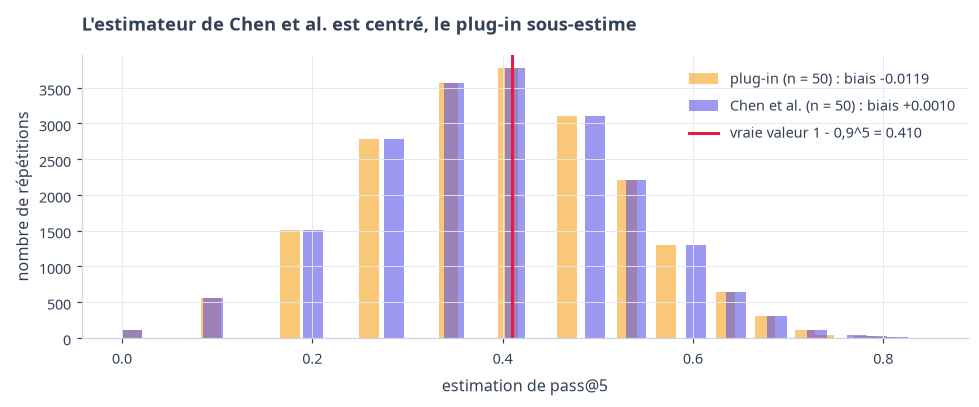

,moyenne,biais,écart-type
k échantillons seulement,0.416,0.007,0.493
plug-in (n = 50),0.398,-0.012,0.136
Chen et al. (n = 50),0.411,0.001,0.139


In [4]:
rng = np.random.default_rng(0)
p_vrai, k, n = 0.10, 5, 50
reps = 20000
naif, plugin, chen = [], [], []
for _ in range(reps):
    s = rng.random(n) < p_vrai
    naif.append(float(s[:k].any()))
    plugin.append(1 - (1 - s.mean()) ** k)
    chen.append(ev.pass_at_k(n, int(s.sum()), k))
vrai = ev.pass_at_k_true(p_vrai, k)
est = pd.DataFrame({"k échantillons seulement": naif, f"plug-in (n = {n})": plugin, f"Chen et al. (n = {n})": chen})
resume = pd.DataFrame({"moyenne": est.mean(), "biais": est.mean() - vrai, "écart-type": est.std()})
fig, ax = plt.subplots(figsize=(9, 3.8))
for (nom, col), c in zip(est.items(), [GRAY, AMBER, INDIGO]):
    if nom.startswith("k "):
        continue
    ax.hist(col, bins=40, alpha=0.55, color=c, label=f"{nom} : biais {col.mean() - vrai:+.4f}")
ax.axvline(vrai, color=ROSE, lw=2, label=f"vraie valeur 1 - 0,9^5 = {vrai:.3f}")
ax.set_xlabel("estimation de pass@5"); ax.set_ylabel("nombre de répétitions")
ax.set_title("L'estimateur de Chen et al. est centré, le plug-in sous-estime")
ax.legend()
plt.tight_layout(); plt.show()
resume

L'estimateur naïf (k échantillons) est sans biais mais son écart-type est énorme (c'est
une variable 0/1). L'estimateur de Chen et al. est sans biais **et** bien plus précis,
car il exploite les $n = 50$ échantillons. Le plug-in sous-estime systématiquement.
Visualisons enfin $\widehat{\text{pass@}k}$ en fonction de $k$ pour quelques valeurs de
$c$ sur $n = 20$ : un problème résolu une fois sur vingt a déjà un pass@10 de 50 %.

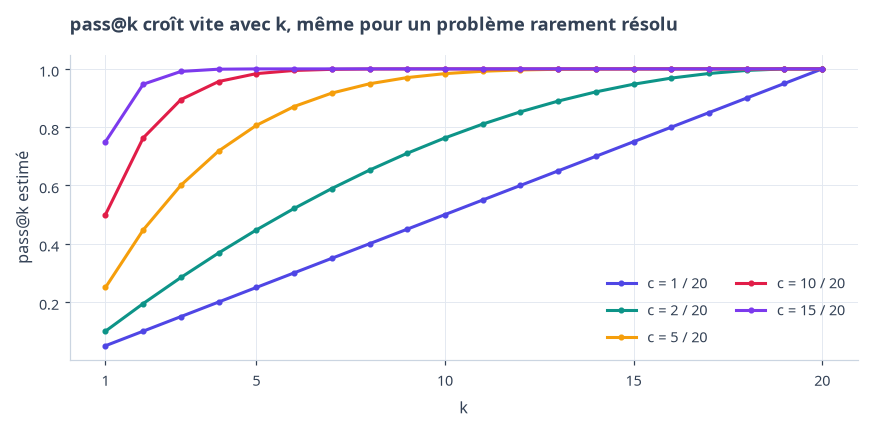

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
ks = np.arange(1, 21)
for c, col in zip([1, 2, 5, 10, 15], COLORS):
    ax.plot(ks, [ev.pass_at_k(20, c, kk) for kk in ks], "o-", ms=3, color=col, label=f"c = {c} / 20")
ax.set_xlabel("k"); ax.set_ylabel("pass@k estimé"); ax.set_xticks([1, 5, 10, 15, 20])
ax.set_title("pass@k croît vite avec k, même pour un problème rarement résolu")
ax.legend(ncol=2)
plt.tight_layout(); plt.show()

> **À retenir.** pass@k mesure la probabilité qu'au moins un des $k$ essais soit correct.
> On l'estime sans biais avec $n \ge k$ échantillons par
> $1 - \binom{n-c}{k}/\binom nk$, plus précis que k essais isolés et sans le biais du
> plug-in.

## 4. Expérience : Qwen2.5-0.5B sur un mini-banc de tests unitaires

Notre banc (`ev.CODE_PROBLEMS`) contient dix problèmes de difficulté croissante, chacun
avec 3 à 5 tests. Pour chaque problème, on génère $n = 20$ programmes en un seul lot
(température 0,8, puis 0,2) et une réponse gloutonne, puis on exécute les tests. Les
énoncés sont en anglais, langue majoritaire des données de code du modèle.

In [6]:
print(ev.code_prompt(ev.CODE_PROBLEMS[4]))

Write a Python function with this exact signature:

def run_length_encode(s: str) -> str:

Run-length encode s: each maximal run of a character c of length n becomes c followed by n. Example: 'aaabcc' -> 'a3b1c2'.
Answer with the code only, in a single ```python block: no explanation, no docstring, no comments, no usage examples.


In [7]:
N = 20
t0 = time.time()
resultats, textes = [], {}
for pb in ev.CODE_PROBLEMS:
    for T in [0.8, 0.2]:
        sorties = ev.sample_solutions(pb, llm.SMALL, n=N, temperature=T)
        textes[(pb["name"], T)] = sorties
        for j, s in enumerate(sorties):
            r = ev.run_tests(ev.extract_code(s), pb["tests"])
            resultats.append(dict(probleme=pb["name"], T=T, ech=j, ok=r.passed, erreur=r.error or "aucune",
                                  frac=r.n_passed / r.n_tests))
    g = ev.sample_solutions(pb, llm.SMALL, temperature=0)[0]
    textes[(pb["name"], 0)] = [g]
    r = ev.run_tests(ev.extract_code(g), pb["tests"])
    resultats.append(dict(probleme=pb["name"], T=0.0, ech=0, ok=r.passed, erreur=r.error or "aucune",
                          frac=r.n_passed / r.n_tests))
R = pd.DataFrame(resultats)
print(f"{len(R)} programmes générés et testés en {time.time() - t0:.0f} s")

410 programmes générés et testés en 179 s


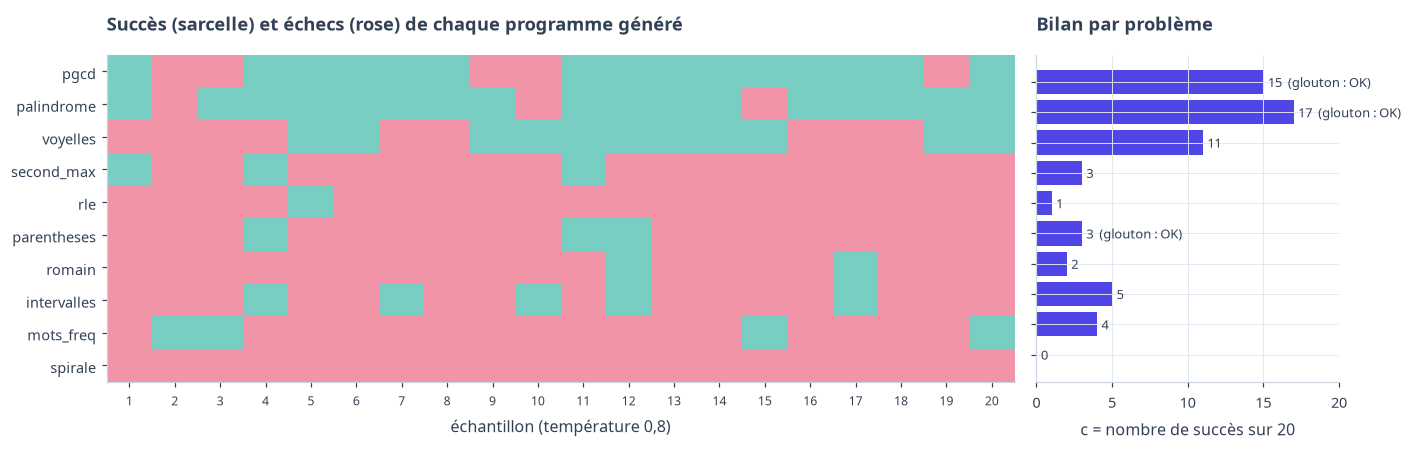

In [8]:
ordre = [pb["name"] for pb in ev.CODE_PROBLEMS]
M = R[R["T"] == 0.8].pivot(index="probleme", columns="ech", values="ok").loc[ordre].astype(float)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw=dict(width_ratios=[3, 1]))
ax.imshow(M.values, cmap="aie_div", vmin=-0.2, vmax=1.2, aspect="auto")
ax.set_yticks(range(len(ordre))); ax.set_yticklabels(ordre)
ax.set_xticks(range(N)); ax.set_xticklabels(range(1, N + 1), fontsize=8)
ax.set_xlabel("échantillon (température 0,8)")
ax.set_title("Succès (sarcelle) et échecs (rose) de chaque programme généré")
ax.grid(False)
c = M.sum(axis=1)
ax2.barh(range(len(ordre)), c.values, color=INDIGO)
ax2.set_yticks(range(len(ordre))); ax2.set_yticklabels([]); ax2.invert_yaxis()
ax2.set_xlim(0, N); ax2.set_xlabel(f"c = nombre de succès sur {N}")
glouton = R[R["T"] == 0.0].set_index("probleme").loc[ordre, "ok"]
for i, (cc, gg) in enumerate(zip(c.values, glouton.values)):
    ax2.text(cc + 0.3, i, f"{cc:.0f}" + ("  (glouton : OK)" if gg else ""), va="center", fontsize=8.5)
ax2.set_title("Bilan par problème")
plt.tight_layout(); plt.show()

Le modèle de 0,5 milliard de paramètres résout de façon fiable les problèmes simples
(PGCD, palindrome) et échoue presque toujours sur les problèmes qui demandent plus de
soin (spirale, codage par plages). La réponse gloutonne, elle, ne donne qu'un verdict
binaire par problème : elle peut échouer sur un problème que l'échantillonnage résout
souvent, et inversement.

Calculons pass@k sur le banc (moyenne des estimateurs par problème) pour les deux
températures.

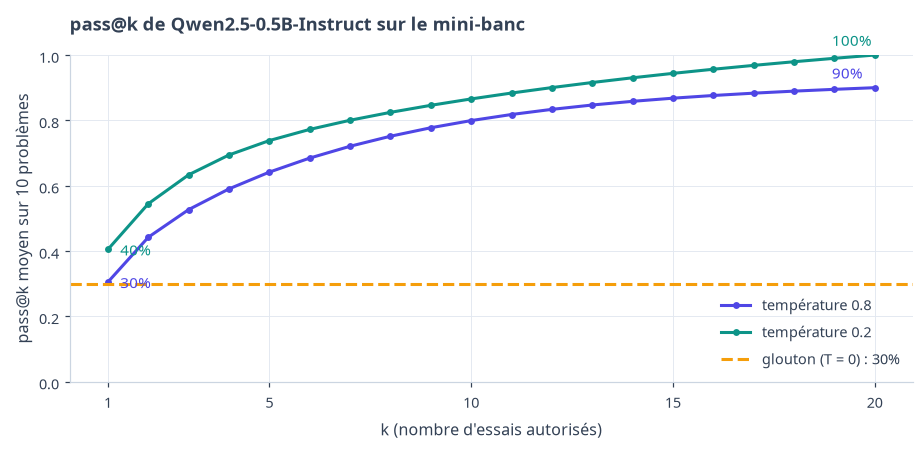

In [9]:
fig, ax = plt.subplots(figsize=(8.5, 4.2))
ks = np.arange(1, N + 1)
courbes = {}
for T, col in [(0.8, INDIGO), (0.2, TEAL)]:
    cT = R[R["T"] == T].groupby("probleme").ok.sum()
    courbes[T] = [np.mean([ev.pass_at_k(N, int(ci), kk) for ci in cT]) for kk in ks]
    ax.plot(ks, courbes[T], "o-", ms=3.5, color=col, label=f"température {T}")
    ax.annotate(f"{courbes[T][0]:.0%}", (1, courbes[T][0]), (8, -4), textcoords="offset points", color=col)
    ax.annotate(f"{courbes[T][-1]:.0%}", (N, courbes[T][-1]), (-28, 6), textcoords="offset points", color=col)
ax.axhline(glouton.mean(), color=AMBER, ls="--", label=f"glouton (T = 0) : {glouton.mean():.0%}")
ax.set_xlabel("k (nombre d'essais autorisés)"); ax.set_ylabel("pass@k moyen sur 10 problèmes")
ax.set_ylim(0, 1); ax.set_xticks([1, 5, 10, 15, 20])
ax.set_title("pass@k de Qwen2.5-0.5B-Instruct sur le mini-banc")
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

Trois observations :

- pass@k croît fortement avec $k$ : autoriser plusieurs essais (avec un vérificateur pour
  choisir, comme les tests ici) transforme un modèle médiocre en pass@1 en un modèle
  utile, idée reprise par le « test-time compute » du chapitre 2 ;
- le décodage glouton n'est qu'un point isolé, comparable à pass@1 ;
- la température joue sur le compromis précision / diversité. En théorie, une
  température haute diversifie les essais et profite aux grands $k$ ; mais pour un petit
  modèle, elle produit aussi beaucoup plus de programmes cassés, si bien que la
  température basse peut dominer à tous les $k$. C'est pourquoi les rapports techniques
  précisent la température utilisée pour chaque valeur de $k$.

(Avec seulement dix problèmes, des écarts de quelques points ne sont pas significatifs :
le chapitre 4 reviendra sur la taille des jeux d'évaluation.)

**Pourquoi échoue-t-il ?** La nature des erreurs guide l'amélioration du système (un
prompt plus directif, un post-traitement, un modèle plus grand).

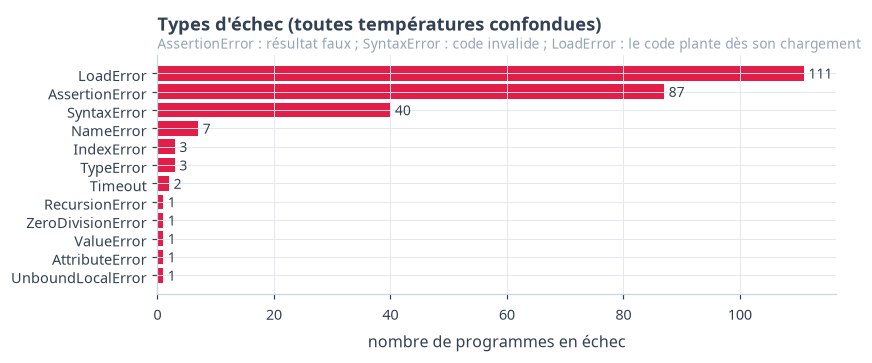

In [10]:
err = R[(R["T"] > 0) & (~R.ok)].erreur.value_counts()
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.barh(err.index[::-1], err.values[::-1], color=ROSE)
annotate_bars(ax, "{:.0f}")
ax.set_xlabel("nombre de programmes en échec")
ax.set_title("Types d'échec (toutes températures confondues)")
subtitle(ax, "AssertionError : résultat faux ; SyntaxError : code invalide ; LoadError : le code plante dès son chargement")
plt.tight_layout(); plt.show()

Beaucoup d'échecs ne viennent pas de l'algorithme mais de la **forme** : malgré la
consigne, le petit modèle ajoute souvent des exemples d'utilisation ou ses propres tests
(parfois faux) qui plantent au chargement (`LoadError`), ou une génération tronquée
(`SyntaxError`). Un harnais d'évaluation applique donc en général un **post-traitement**
: `ev.sanitize_code` ne garde que les `import`, `def` et `class` de premier niveau, après
avoir retiré les lignes finales incomplètes. Mesurons l'effet de ce choix de harnais sur
les mêmes 400 programmes.

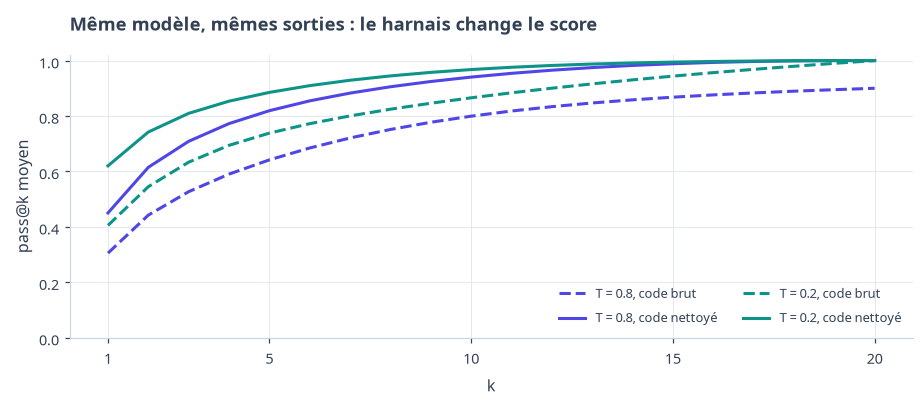

,pass@1 brut,pass@1 nettoyé
T,,
0.2,0.405,0.62
0.8,0.305,0.45


In [11]:
rows = []
for pb in ev.CODE_PROBLEMS:
    for T in [0.8, 0.2]:
        for s_ in textes[(pb["name"], T)]:
            brut = ev.extract_code(s_)
            rows.append(dict(probleme=pb["name"], T=T, brut=ev.run_tests(brut, pb["tests"]).passed,
                             nettoye=ev.run_tests(ev.sanitize_code(brut), pb["tests"]).passed))
SAN = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for T, col in [(0.8, INDIGO), (0.2, TEAL)]:
    for mode, ls in [("brut", "--"), ("nettoye", "-")]:
        cT = SAN[SAN["T"] == T].groupby("probleme")[mode].sum()
        ax.plot(ks, [np.mean([ev.pass_at_k(N, int(ci), kk) for ci in cT]) for kk in ks], ls, color=col,
                label=f"T = {T}, code {'nettoyé' if mode == 'nettoye' else 'brut'}")
ax.set_xlabel("k"); ax.set_ylabel("pass@k moyen"); ax.set_ylim(0, 1.02); ax.set_xticks([1, 5, 10, 15, 20])
ax.set_title("Même modèle, mêmes sorties : le harnais change le score")
ax.legend(loc="lower right", ncol=2, fontsize=8.5)
plt.tight_layout(); plt.show()
SAN.groupby("T")[["brut", "nettoye"]].mean().rename(columns={"brut": "pass@1 brut", "nettoye": "pass@1 nettoyé"})

Le score d'un modèle dépend donc aussi de détails du harnais (extraction, nettoyage,
délai, prompt) : deux équipes qui annoncent un « pass@1 sur HumanEval » ne mesurent pas
forcément la même chose. Un exemple de programme qui passe et un qui échoue, pour le
même problème (commentaires retirés pour l'affichage, le modèle en a mis malgré la
consigne) :

In [12]:
nom = "parentheses"
pbp = next(p for p in ev.CODE_PROBLEMS if p["name"] == nom)
ech = textes[(nom, 0.8)]
oks = [ev.run_tests(ev.extract_code(s), pbp["tests"]).passed for s in ech]
for etiquette, cible in [("RÉUSSI", True), ("ÉCHOUÉ", False)]:
    if cible in oks:
        code = ev.extract_code(ech[oks.index(cible)])
        lignes = [l for l in code.splitlines() if l.strip() and not l.strip().startswith("#")]
        print(f"--- {etiquette} ---\n" + "\n".join(lignes[:18]) + ("\n    [...]" if len(lignes) > 18 else "") + "\n")

--- RÉUSSI ---
def is_balanced(s: str) -> bool:
    stack = []
    for char in s:
        if char == '(' or char == '[' or char == '{':
            stack.append(char)
        elif char == ')' or char == ']' or char == '}':
            if not stack:
                return False
            pop_char = stack.pop()
            if (char == ')' and pop_char != '(') or \
               (char == ']' and pop_char != '[') or \
               (char == '}' and pop_char != '{'):
                return False
    return len(stack) == 0
print(is_balanced("()"))          # Output: True
print(is_balanced("(]"))          # Output: False
print(is_balanced("({[]})"))      # Output: True
print(is_balanced("({[}])"))      # Output: False

--- ÉCHOUÉ ---
def is_balanced(s):
    """
    Check if the brackets '(' , ')' , '[' , ']' and '{'} in string s are balanced and properly nested.
    Parameters:
    s (str): The input string containing brackets to be checked.
    Returns:
    bool: True if the strings of a

> **À retenir.** Sur des problèmes de code munis de tests, l'évaluation est entièrement
> automatique : on échantillonne, on exécute, on calcule pass@k. Le score dépend de $k$,
> de la température et de la difficulté du banc : un pass@k ne se lit qu'avec ces
> paramètres.

## 5. Correspondance exacte (sections *Similarity Measurements Against Reference Data* et *Exact match*)

Quand la tâche ne s'exécute pas (traduction, question factuelle), on compare la sortie à
des **réponses de référence** (« ground truths », « canonical responses »). Les
métriques qui en ont besoin sont dites *reference-based*. Le livre en distingue trois :
correspondance exacte (binaire), similarité lexicale et similarité sémantique (continues).

La correspondance exacte marche pour les réponses courtes et fermées (« 2 + 3 ? »). On
**normalise** d'abord (minuscules, ponctuation, articles, espaces : convention de
SQuAD). Une variante laxiste accepte toute sortie qui **contient** la référence, au prix
de faux positifs, comme dans l'exemple d'Anne Frank du livre.

In [13]:
cas = [
    ("What's 2 + 3?", "5", ["5"]),
    ("What's 2 + 3?", "The answer is 5.", ["5"]),
    ("What's 2 + 3?", "2 + 3 is 5", ["5"]),
    ("What's 2 + 3?", "It is not 5, it is 6.", ["5"]),
    ("What year was Anne Frank born?", "September 12, 1929", ["1929"]),
    ("Capital of France?", "the city of Paris", ["Paris"]),
    ("Comment ça va ? (en anglais)", "How is it going?", ["How are you?", "How is everything?", "How are you doing?"]),
    ("Comment ça va ? (en anglais)", "how are you", ["How are you?", "How is everything?", "How are you doing?"]),
]
tab = pd.DataFrame([dict(question=q, sortie=s, exacte_brute=ev.exact_match(s, r, normalize=False),
                         exacte_normalisee=ev.exact_match(s, r), contient=ev.contains_match(s, r),
                         f1_mots=max(ev.token_f1(s, x) for x in r)) for q, s, r in cas])
tab

,question,sortie,exacte_brute,exacte_normalisee,contient,f1_mots
0,What's 2 + 3?,5,True,True,True,1.000
1,What's 2 + 3?,The answer is 5.,False,False,True,0.500
2,What's 2 + 3?,2 + 3 is 5,False,False,True,0.400
3,What's 2 + 3?,"It is not 5, it is 6.",False,False,True,0.250
4,What year was Anne Frank born?,"September 12, 1929",False,False,True,0.500
5,Capital of France?,the city of Paris,False,False,True,0.500
6,Comment ça va ? (en anglais),How is it going?,False,False,False,0.571
7,Comment ça va ? (en anglais),how are you,False,True,True,1.000


Lecture ligne par ligne :

- la normalisation corrige les différences de forme (« how are you » contre « How are
  you? ») ;
- l'inclusion accepte « The answer is 5 » mais aussi « It is not 5, it is 6 » et la date
  fausse d'Anne Frank : **faux positifs** ;
- « How is it going? » est une traduction correcte absente des références :
  **faux négatif**. Plus le texte est long, plus l'ensemble des bonnes réponses est grand
  et plus la correspondance exacte est inutilisable ;
- le F1 sur les mots (SQuAD) donne un crédit partiel, première étape vers la similarité
  lexicale.

> **À retenir.** La correspondance exacte (après normalisation) convient aux réponses
> courtes et fermées. La variante « contient » est pratique mais laisse passer des
> réponses fausses ; aucune des deux ne survit aux réponses longues.

## 6. Similarité lexicale : distance d'édition, n-grammes, BLEU, ROUGE (section *Lexical similarity*)

### 6.1 Distance d'édition

La **distance de Levenshtein** compte le nombre minimal d'opérations (suppression,
insertion, substitution) pour passer d'une chaîne à l'autre. Elle se calcule par
programmation dynamique : en notant $D[i, j]$ la distance entre les $i$ premiers
caractères de $a$ et les $j$ premiers de $b$,
$$D[i, j] = \min\big(D[i-1, j] + 1,\; D[i, j-1] + 1,\; D[i-1, j-1] + \mathbb 1[a_i \ne b_j]\big),$$
avec $D[i, 0] = i$ et $D[0, j] = j$. Coût en $O(|a|\,|b|)$. Visualisons la table pour
l'exemple du livre « bad » contre « cash » (3 éditions) et « bad » contre « bard »
(1 édition).

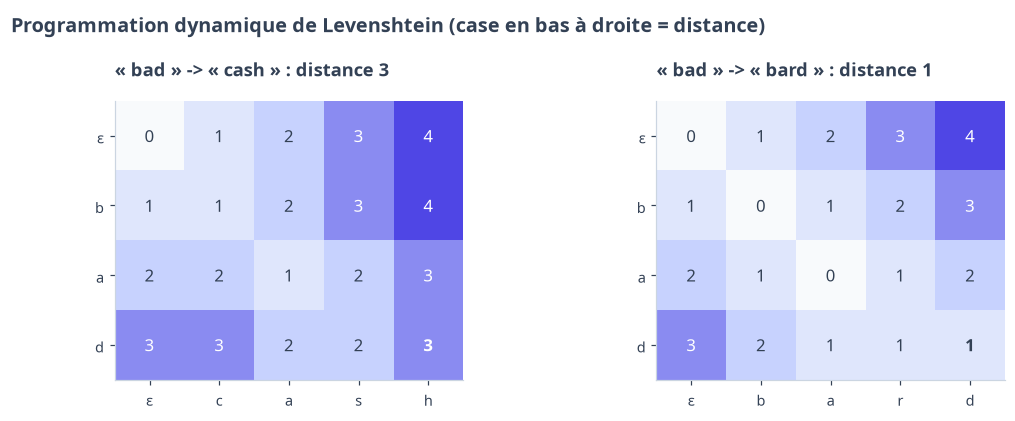

,paire,levenshtein,avec_transpositions
0,brad -> bad,1,1
1,bad -> bard,1,1
2,bad -> bed,1,1
3,bad -> cash,3,3
4,mats -> mast,2,1


In [14]:
def table_levenshtein(a, b):
    D = np.zeros((len(a) + 1, len(b) + 1), dtype=int)
    D[:, 0], D[0, :] = range(len(a) + 1), range(len(b) + 1)
    for i in range(1, len(a) + 1):
        for j in range(1, len(b) + 1):
            D[i, j] = min(D[i - 1, j] + 1, D[i, j - 1] + 1, D[i - 1, j - 1] + (a[i - 1] != b[j - 1]))
    return D


fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for ax, (a, b) in zip(axes, [("bad", "cash"), ("bad", "bard")]):
    D = table_levenshtein(a, b)
    ax.imshow(D, cmap="aie_seq", vmin=0, vmax=D.max() + 2)
    for i in range(D.shape[0]):
        for j in range(D.shape[1]):
            ax.text(j, i, D[i, j], ha="center", va="center", fontsize=11,
                    color="white" if D[i, j] > D.max() * 0.6 else SLATE,
                    fontweight="bold" if (i, j) == (len(a), len(b)) else None)
    ax.set_xticks(range(len(b) + 1)); ax.set_xticklabels(["ε"] + list(b))
    ax.set_yticks(range(len(a) + 1)); ax.set_yticklabels(["ε"] + list(a))
    ax.set_title(f"« {a} » -> « {b} » : distance {D[-1, -1]}"); ax.grid(False)
finish(fig, "Programmation dynamique de Levenshtein (case en bas à droite = distance)")
plt.show()
pd.DataFrame([dict(paire=f"{a} -> {b}", levenshtein=ev.edit_distance(a, b),
                   avec_transpositions=ev.edit_distance(a, b, transpositions=True))
              for a, b in [("brad", "bad"), ("bad", "bard"), ("bad", "bed"), ("bad", "cash"), ("mats", "mast")]])

Comme le note le livre, une transposition (« mats » -> « mast ») compte pour 2 éditions
chez Levenshtein, pour 1 si l'on ajoute l'échange de deux lettres adjacentes.

### 6.2 Recouvrement de n-grammes

Un **n-gramme** est une suite de $n$ tokens consécutifs. L'exemple du livre : la
référence « My cats scare the mice » contre A = « My cats eat the mice » et
B = « Cats and mice fight all the time ».

In [15]:
ref = "My cats scare the mice"
A, B = "My cats eat the mice", "Cats and mice fight all the time"
r = []
for nom, cand in [("A", A), ("B", B)]:
    for n in [1, 2]:
        rn = ev.rouge_n(cand, ref, n)
        r.append(dict(candidat=nom, n=n, ngrammes_ref=sum(ev.ngrams(ev.words(ref), n).values()),
                      communs=round(rn["rappel"] * sum(ev.ngrams(ev.words(ref), n).values())),
                      rappel=rn["rappel"], precision=rn["precision"]))
pd.DataFrame(r)

,candidat,n,ngrammes_ref,communs,rappel,precision
0,A,1,5,4,0.8,0.800
1,A,2,4,2,0.5,0.500
2,B,1,5,3,0.6,0.429
3,B,2,4,0,0.0,0.000


A partage 4 des 5 mots de la référence (80 %), B en partage 3 (60 %), comme dans le
livre. Les bigrammes séparent encore plus nettement les deux candidats (A : « my cats »
et « the mice » ; B : aucun).

### 6.3 BLEU et ROUGE

**BLEU** (Papineni et al., 2002), conçu pour la traduction, est orienté **précision** :
$$\mathrm{BLEU} = \mathrm{BP}\cdot \exp\Big(\frac14 \sum_{n=1}^{4} \log p_n\Big), \qquad
\mathrm{BP} = \min\big(1, e^{1 - r/c}\big),$$
où $p_n$ est la précision des n-grammes **écrêtée** (un n-gramme du candidat ne compte
pas plus de fois qu'il n'apparaît dans une référence, sinon « the the the the » aurait
une précision parfaite) et $\mathrm{BP}$ la **pénalité de brièveté** ($c$ : longueur du
candidat, $r$ : longueur de la référence la plus proche), sans laquelle un candidat d'un
seul mot juste obtiendrait 100 %.

**ROUGE** (Lin, 2004), conçu pour le résumé, est orienté **rappel** : ROUGE-N mesure la
part des n-grammes de la référence retrouvés ; ROUGE-L utilise la plus longue
sous-séquence commune (LCS), qui récompense l'ordre des mots sans exiger la contiguïté.

Décomposons BLEU sur un exemple de traduction.

In [16]:
refs = ["The cat is sitting on the mat.", "There is a cat on the mat."]
cands = {"bonne traduction": "The cat is sitting on the mat.", "paraphrase": "A cat sits on the rug.",
         "ordre cassé": "mat the on sitting is cat the", "trop courte": "The cat.",
         "répétitive": "the the the the the the the"}
lignes = []
for nom, c in cands.items():
    cw = ev.words(c)
    ps = []
    for n in range(1, 5):
        cng = ev.ngrams(cw, n)
        mx = Counter()
        for rr in refs:
            mx |= ev.ngrams(ev.words(rr), n)
        ps.append(sum(min(v, mx[g]) for g, v in cng.items()) / max(1, sum(cng.values())))
    rl = min((abs(len(ev.words(rr)) - len(cw)), len(ev.words(rr))) for rr in refs)[1]
    lignes.append(dict(candidat=nom, p1=ps[0], p2=ps[1], p3=ps[2], p4=ps[3],
                       BP=1.0 if len(cw) > rl else math.exp(1 - rl / len(cw)),
                       BLEU=ev.bleu(c, refs), ROUGE_1=max(ev.rouge_n(c, rr, 1)["f1"] for rr in refs),
                       ROUGE_L=max(ev.rouge_l(c, rr)["f1"] for rr in refs)))
bl = pd.DataFrame(lignes).set_index("candidat")
bl

,p1,p2,p3,p4,BP,BLEU,ROUGE_1,ROUGE_L
candidat,,,,,,,,
bonne traduction,1.000,1.0,1.0,1.0,1.000,1.000,1.000,1.000
paraphrase,0.667,0.4,0.0,0.0,0.846,0.304,0.615,0.615
ordre cassé,1.000,0.0,0.0,0.0,1.000,0.263,1.000,0.429
trop courte,1.000,1.0,0.0,0.0,0.082,0.058,0.444,0.444
répétitive,0.286,0.0,0.0,0.0,1.000,0.192,0.286,0.286


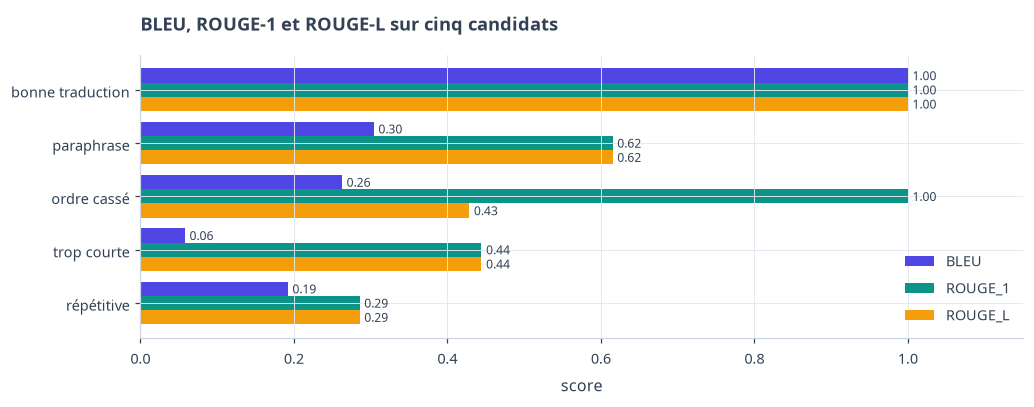

In [17]:
fig, ax = plt.subplots(figsize=(9.5, 3.8))
bl[["BLEU", "ROUGE_1", "ROUGE_L"]].plot.barh(ax=ax, color=[INDIGO, TEAL, AMBER], width=0.8)
ax.invert_yaxis(); ax.set_xlim(0, 1.15); ax.set_xlabel("score"); ax.set_ylabel("")
ax.set_title("BLEU, ROUGE-1 et ROUGE-L sur cinq candidats")
annotate_bars(ax, "{:.2f}", fontsize=8)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

(Les colonnes $p_n$ sont les précisions brutes ; le BLEU affiché applique le lissage
« +1 » pour $n \ge 2$, sans lequel une seule précision nulle annulerait le score d'une
phrase courte.)

- « ordre cassé » a les mêmes mots que la référence : ROUGE-1 vaut 1, mais BLEU (via les
  n-grammes d'ordre 2 à 4) et ROUGE-L (via la LCS) le pénalisent ;
- « trop courte » a une précision parfaite mais la pénalité de brièveté fait chuter BLEU ;
- « répétitive » est neutralisée par l'écrêtage ;
- la **paraphrase**, pourtant correcte, obtient des scores médiocres : c'est le défaut
  fondamental des métriques lexicales.

> **À retenir.** Distance d'édition, recouvrement de n-grammes, BLEU (précision écrêtée
> et pénalité de brièveté) et ROUGE (rappel, LCS) mesurent à quel point deux textes se
> **ressemblent en surface**. Leurs garde-fous (écrêtage, brièveté, ordre) corrigent les
> tricheries évidentes, pas l'aveuglement au sens.

## 7. Les limites des métriques lexicales (section *Lexical similarity*)

Le livre relève deux limites majeures.

**1. Les références sont incomplètes (ou fausses).** Une bonne réponse absente des
références est pénalisée (l'exemple de Fuyu chez Adept, les mauvaises traductions de
référence du WMT 2023). Mesurons l'effet du nombre de références : on fait traduire
« Comment ça va ? » trente fois à Qwen (température 1, comme au cours 1), puis on note
ces mêmes traductions en ajoutant les références une à une.

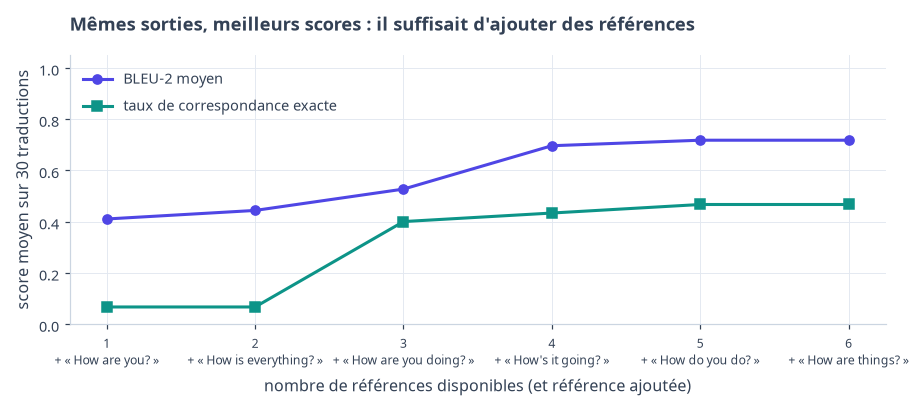

In [18]:
trads = [llm.chat("Translate into English, answer with the translation only: « Comment ça va ? »",
                  temperature=1.0, seed=s, max_new_tokens=15).strip().strip('"') for s in range(30)]
pool_refs = ["How are you?", "How is everything?", "How are you doing?", "How's it going?", "How do you do?",
             "How are things?"]
moy = [np.mean([ev.bleu(t, pool_refs[:m], max_n=2) for t in trads]) for m in range(1, len(pool_refs) + 1)]
em = [np.mean([ev.exact_match(t, pool_refs[:m]) for t in trads]) for m in range(1, len(pool_refs) + 1)]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
x = np.arange(1, len(pool_refs) + 1)
ax.plot(x, moy, "o-", color=INDIGO, label="BLEU-2 moyen")
ax.plot(x, em, "s-", color=TEAL, label="taux de correspondance exacte")
ax.set_xticks(x); ax.set_xticklabels([f"{xi}\n+ « {r_} »" for xi, r_ in zip(x, pool_refs)], fontsize=8)
ax.set_xlabel("nombre de références disponibles (et référence ajoutée)"); ax.set_ylabel("score moyen sur 30 traductions")
ax.set_ylim(0, 1.05)
ax.set_title("Mêmes sorties, meilleurs scores : il suffisait d'ajouter des références")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

Les sorties n'ont pas changé, seul l'ensemble de références a grandi : le score mesure
autant la **couverture des références** que la qualité du modèle.

**2. Une forte similarité lexicale n'implique pas une bonne réponse.** Sur HumanEval,
OpenAI a constaté que les scores BLEU des solutions correctes et incorrectes étaient
proches (Chen et al., 2021). Vérifions-le avec nos 400 programmes de la section 4 : on
calcule le BLEU de chacun contre la solution canonique du problème et l'on compare les
distributions des programmes qui passent les tests et de ceux qui échouent.

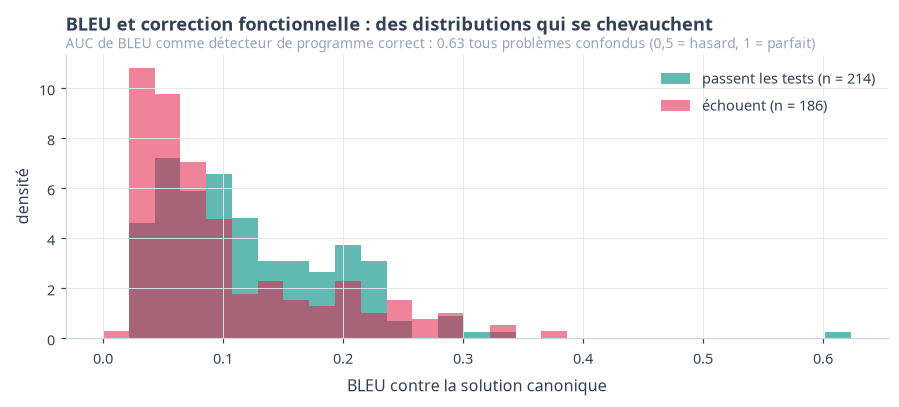

,intervalles,mots_freq,palindrome,parentheses,pgcd,rle,romain,second_max,spirale,voyelles
AUC à problème fixé,0.78,0.54,0.78,0.44,0.85,0.46,0.55,0.64,0.5,0.45


In [19]:
rows = []
for pb in ev.CODE_PROBLEMS:
    for T in [0.8, 0.2]:
        for s in textes[(pb["name"], T)]:
            code = ev.sanitize_code(ev.extract_code(s))   # sans commentaires ni exemples
            rows.append(dict(probleme=pb["name"], ok=ev.run_tests(code, pb["tests"]).passed,
                             bleu=ev.bleu(code, ev.REFERENCE_SOLUTIONS[pb["name"]])))
BC = pd.DataFrame(rows)
from sklearn.metrics import roc_auc_score

auc = roc_auc_score(BC.ok, BC.bleu)
auc_intra = {k: roc_auc_score(g.ok, g.bleu) for k, g in BC.groupby("probleme") if 0 < g.ok.sum() < len(g)}
fig, ax = plt.subplots(figsize=(8.5, 3.8))
bins = np.linspace(0, BC.bleu.max() + 0.02, 30)
ax.hist(BC[BC.ok].bleu, bins=bins, alpha=0.65, color=TEAL, density=True, label=f"passent les tests (n = {BC.ok.sum()})")
ax.hist(BC[~BC.ok].bleu, bins=bins, alpha=0.55, color=ROSE, density=True, label=f"échouent (n = {(~BC.ok).sum()})")
ax.set_xlabel("BLEU contre la solution canonique"); ax.set_ylabel("densité")
ax.set_title("BLEU et correction fonctionnelle : des distributions qui se chevauchent")
subtitle(ax, f"AUC de BLEU comme détecteur de programme correct : {auc:.2f} tous problèmes confondus "
             f"(0,5 = hasard, 1 = parfait)")
ax.legend()
plt.tight_layout(); plt.show()
pd.Series(auc_intra, name="AUC à problème fixé").to_frame().T.round(2)

Les deux distributions se chevauchent largement : un programme peut être lexicalement
proche de la solution et faux (un `<` au lieu d'un `<=`), ou très différent et correct
(un autre algorithme). Le pouvoir de séparation global est en partie un artefact : les
problèmes faciles ont à la fois des solutions courtes, proches de la référence, et un
taux de réussite élevé. Le tableau des AUC **à problème fixé** le montre : pour un même
problème, BLEU devient un détecteur très irrégulier, parfois pire que le hasard. Optimiser
BLEU n'est pas optimiser la correction fonctionnelle.

> **À retenir.** Les métriques lexicales sont bon marché, exactes et reproductibles,
> mais elles dépendent de la couverture des références et ne mesurent pas la justesse.
> Elles restent utiles pour la traduction, le sous-titrage ou la détection de
> quasi-doublons, beaucoup moins pour juger des réponses ouvertes.

## Synthèse

- **Évaluation exacte** : verdict indépendant de l'évaluateur. Deux familles pour les
  sorties ouvertes : correction fonctionnelle et similarité avec des références.
- **Correction fonctionnelle** : exécuter la sortie sur des tests (code, SQL, jeux) ;
  métrique ultime quand elle est automatisable ; exige des tests riches et un bac à
  sable.
- **pass@k** $= 1-(1-p)^k$, estimé sans biais par $1 - \binom{n-c}{k}/\binom nk$ ; il
  dépend de $k$ et de la température (compromis diversité / précision).
- **Correspondance exacte** : pour réponses courtes ; normaliser ; méfiance envers
  l'inclusion (faux positifs).
- **Similarité lexicale** : édition, n-grammes, BLEU (précision, brièveté), ROUGE
  (rappel, LCS) ; limitée par la couverture des références et aveugle au sens.

**Liens.** Le cours 3 remplace la forme par le sens (embeddings, similarité cosinus) puis
introduit les juges IA ; le chapitre 4 construira des pipelines d'évaluation combinant ces
méthodes ; la distance d'édition et les n-grammes reviendront pour la déduplication de
données (chapitre 8).

In [20]:
llm.free_gpu()